<a href="https://colab.research.google.com/github/shreyashkhedkar07/Sales-Data-Filter-Report-Engine/blob/main/Sales_Data_Filter_and_Report_Engine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sales Data Filter & Report Engine
### Beginner-friendly NumPy project

**Goal:** Simulate 12 months of sales for 10 stores, filter the data, compare quarterly performance, and create simple reports.

This follows **Project 3** in your uploaded *5 NumPy Projects for Your Resume* guide (page 6). All sales figures are randomly generated for learning; they are not real business data.


## 1. Import NumPy and generate sample sales data

Each row represents a store and each column represents a month. Sales are measured in rupees for this example.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

months = np.arange(1, 13)
store_names = np.array([f"Store {i}" for i in range(1, 11)])

# Simulated monthly sales in rupees, from ₹20,000 to ₹99,999.
sales = np.random.randint(20_000, 100_000, size=(10, 12))

print("Sales array shape:", sales.shape)
print("Number of dimensions:", sales.ndim)
print("Total monthly records:", sales.size)
print("\nFirst 3 stores:")
print(sales[:3])

Sales array shape: (10, 12)
Number of dimensions: 2
Total monthly records: 120

First 3 stores:
[[35795 20860 96820 74886 26265 57194 64131 80263 36023 61090 87221 84820]
 [20769 79735 82955 84925 87969 25311 73707 48693 91932 45658 38431 22747]
 [79150 85725 55773 87435 76886 86803 51551 31394 89092 23890 61606 30627]]


## 2. View quarterly sales using slicing

Each quarter has three months: Q1 = January–March, Q2 = April–June, Q3 = July–September, and Q4 = October–December.

In [2]:
q1 = sales[:, 0:3]
q2 = sales[:, 3:6]
q3 = sales[:, 6:9]
q4 = sales[:, 9:12]

quarter_totals = np.array([
    q1.sum(),
    q2.sum(),
    q3.sum(),
    q4.sum()
])

print("Total sales by quarter:")
for quarter, total in zip(["Q1", "Q2", "Q3", "Q4"], quarter_totals):
    print(f"{quarter}: ₹{total:,.0f}")

best_quarter = int(quarter_totals.argmax())
print(f"\nBest quarter overall: Q{best_quarter + 1}")

Total sales by quarter:
Q1: ₹1,784,124
Q2: ₹1,979,431
Q3: ₹1,760,380
Q4: ₹1,830,198

Best quarter overall: Q2


## 3. Create a store-wise report

Calculate each store's total annual sales and average monthly sales, then sort stores from highest to lowest total sales.

In [3]:
store_totals = sales.sum(axis=1)
store_monthly_average = sales.mean(axis=1)

order = np.argsort(store_totals)[::-1]

print(f"{'Store':<12}{'Annual sales':>18}{'Monthly average':>20}")
print("-" * 50)
for idx in order:
    print(f"{store_names[idx]:<12}₹{store_totals[idx]:>16,.0f}₹{store_monthly_average[idx]:>18,.0f}")

print(f"\nTop-performing store: {store_names[order[0]]}")

Store             Annual sales     Monthly average
--------------------------------------------------
Store 5     ₹         877,740₹            73,145
Store 9     ₹         850,413₹            70,868
Store 4     ₹         796,076₹            66,340
Store 3     ₹         759,932₹            63,328
Store 1     ₹         725,368₹            60,447
Store 10    ₹         719,021₹            59,918
Store 2     ₹         702,832₹            58,569
Store 7     ₹         677,681₹            56,473
Store 6     ₹         627,012₹            52,251
Store 8     ₹         618,058₹            51,505

Top-performing store: Store 5


## 4. Filter sales using Boolean masks

Find months where total sales exceed a target and stores whose annual sales are below the average store total.

In [4]:
monthly_totals = sales.sum(axis=0)
target = 500_000

months_above_target = months[monthly_totals > target]
average_store_total = store_totals.mean()
below_average_stores = store_names[store_totals < average_store_total]

print(f"Monthly sales target: ₹{target:,.0f}")
print("Months exceeding target:", months_above_target)
print("Total sales by month:", monthly_totals)
print(f"Average annual sales per store: ₹{average_store_total:,.0f}")
print("Stores below average annual sales:", below_average_stores)

# Combined conditions: stores with annual sales above the average
# AND at least one month with sales greater than ₹90,000.
high_store_mask = (store_totals > average_store_total) & (sales.max(axis=1) > 90_000)
print("Stores above average with at least one month over ₹90,000:",
      store_names[high_store_mask])

Monthly sales target: ₹500,000
Months exceeding target: [ 2  3  4  5  6  7  8  9 10 11 12]
Total sales by month: [442445 681178 660501 702281 626045 651105 506343 623407 630630 587402
 658786 584010]
Average annual sales per store: ₹735,413
Stores below average annual sales: ['Store 1' 'Store 2' 'Store 6' 'Store 7' 'Store 8' 'Store 10']
Stores above average with at least one month over ₹90,000: ['Store 4' 'Store 5' 'Store 9']


## 5. Use fancy indexing to select chosen stores

Fancy indexing lets us select specific rows without taking a continuous range.

In [5]:
selected_store_indices = np.array([1, 4, 7])  # Store 2, Store 5, Store 8
selected_sales = sales[selected_store_indices, :]

print("Sales for Store 2, Store 5, and Store 8:")
print(selected_sales)

# Identify the three highest-selling months overall.
top_month_indices = np.argsort(monthly_totals)[-3:][::-1]
print("\nTop 3 months:")
for idx in top_month_indices:
    print(f"Month {months[idx]}: ₹{monthly_totals[idx]:,.0f}")

Sales for Store 2, Store 5, and Store 8:
[[20769 79735 82955 84925 87969 25311 73707 48693 91932 45658 38431 22747]
 [39457 86557 97189 98953 72995 60757 29692 65758 92409 91211 85697 57065]
 [59504 53159 33986 81858 32666 58660 23561 46854 84505 72251 42662 28392]]

Top 3 months:
Month 4: ₹702,281
Month 2: ₹681,178
Month 3: ₹660,501


## 6. Visualize the results

The first chart compares monthly sales across all stores. The second compares total sales for each quarter.

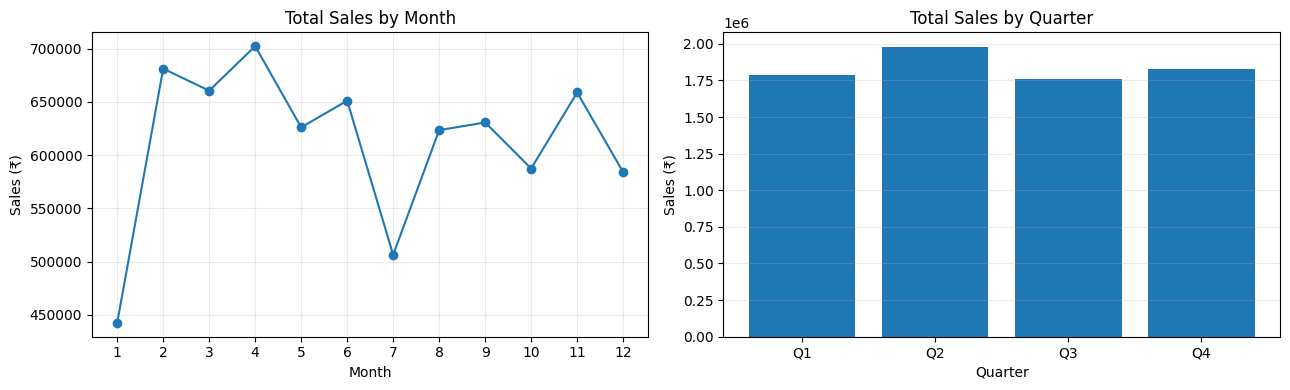

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(months, monthly_totals, marker="o")
axes[0].set_title("Total Sales by Month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Sales (₹)")
axes[0].set_xticks(months)
axes[0].grid(alpha=0.25)

axes[1].bar(["Q1", "Q2", "Q3", "Q4"], quarter_totals)
axes[1].set_title("Total Sales by Quarter")
axes[1].set_xlabel("Quarter")
axes[1].set_ylabel("Sales (₹)")
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## 7. Export the data to CSV

This creates one row per store-month pair, for 120 records in total.

In [7]:
store_index, month_index = np.indices(sales.shape)

import pandas as pd

sales_df = pd.DataFrame({
    "Store": store_names[store_index.ravel()],
    "Month": months[month_index.ravel() - 1],
    "Sales_INR": sales.ravel()
})

csv_path = "sales_data.csv"
sales_df.to_csv(csv_path, index=False)

print(f"Saved {len(sales_df)} rows to {csv_path}")
display(sales_df.head(10))

Saved 120 rows to sales_data.csv


,Store,Month,Sales_INR
0,Store 1,12,35795
1,Store 1,1,20860
2,Store 1,2,96820
3,Store 1,3,74886
4,Store 1,4,26265
5,Store 1,5,57194
6,Store 1,6,64131
7,Store 1,7,80263
8,Store 1,8,36023
9,Store 1,9,61090


## 8. Conclusion

After running all cells, note:
- Which quarter had the highest total sales.
- Which store had the highest annual sales.
- Which months exceeded the target.
- Which stores were below the average.

**NumPy concepts practiced:** `np.arange`, random arrays, `shape`, `ndim`, 2D slicing, `sum`, `mean`, Boolean masks with `&`, `argsort`, and fancy indexing.

### Resume line
Built a NumPy-based sales reporting tool that analyzes simulated store-month data using quarterly slicing, Boolean filtering, fancy indexing, and sales visualizations.
